# Exploratory Data Analysis — Predictive Maintenance (AI4I 2020)

Goal: understand what drives **machine failure** in the [UCI AI4I 2020](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) dataset (10,000 machine records) before modelling.

We look at the target balance, the failure modes, how the sensor readings differ between healthy and failing machines, and correlations — including the physics-informed features engineered in `src/data.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'src').exists() and (ROOT.parent / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from data import load_raw, engineer_features, RAW_NUMERIC, NUMERIC_FEATURES, FAILURE_MODES, TARGET

sns.set_theme(style='whitegrid')
df = engineer_features(load_raw())
print('shape:', df.shape)
df.head()

shape: (10000, 17)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temp difference [K],Power [W],Strain [min*Nm]
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,6951.590560,0.0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,6826.722724,138.9
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,7749.387543,247.0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,5927.504659,276.5
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,5897.816608,360.0


## 1. Target balance — failure is rare
Predictive-maintenance is an **imbalanced** problem, which is why we later evaluate with PR-AUC rather than accuracy.

Failures: 339 / 10000  (3.39%)


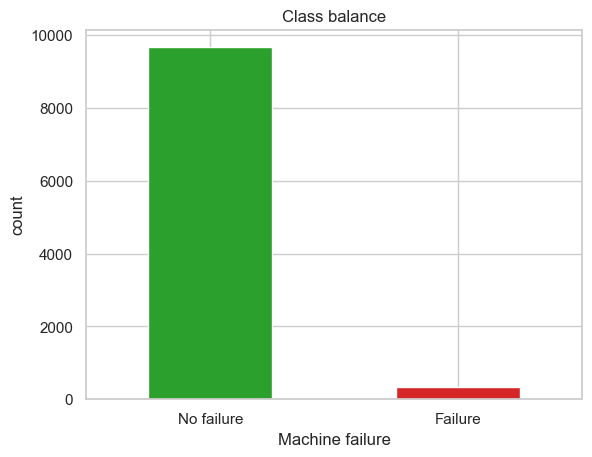

In [2]:
rate = df[TARGET].mean()
print(f'Failures: {df[TARGET].sum()} / {len(df)}  ({rate:.2%})')
ax = df[TARGET].value_counts().rename({0:'No failure',1:'Failure'}).plot.bar(color=['#2ca02c','#d62728'], rot=0)
ax.set_title('Class balance'); ax.set_ylabel('count'); plt.show()

## 2. Failure modes
A failure can be caused by Tool Wear (TWF), Heat Dissipation (HDF), Power (PWF), Overstrain (OSF) or Random (RNF).

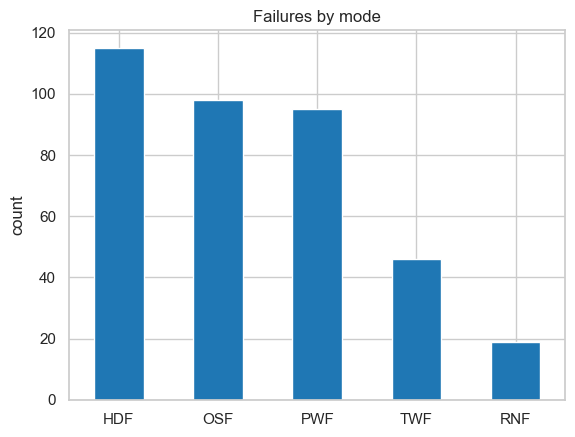

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [3]:
counts = df[FAILURE_MODES].sum().sort_values(ascending=False)
ax = counts.plot.bar(color='#1f77b4', rot=0)
ax.set_title('Failures by mode'); ax.set_ylabel('count'); plt.show()
counts

## 3. Sensor readings: healthy vs failing
Boxplots of each measurement, split by failure, reveal which signals separate the two classes.

C:\Users\o26elaye\AppData\Local\Temp\ipykernel_21624\3931815640.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette=['#2ca02c','#d62728'])
C:\Users\o26elaye\AppData\Local\Temp\ipykernel_21624\3931815640.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No failure','Failure']); ax.set_xlabel('')
C:\Users\o26elaye\AppData\Local\Temp\ipykernel_21624\3931815640.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette=['#2ca02c','#d62728'])
C:\Users\o26elaye\AppData\Local\Temp\ipykernel_21624\3931815640.py:5: User

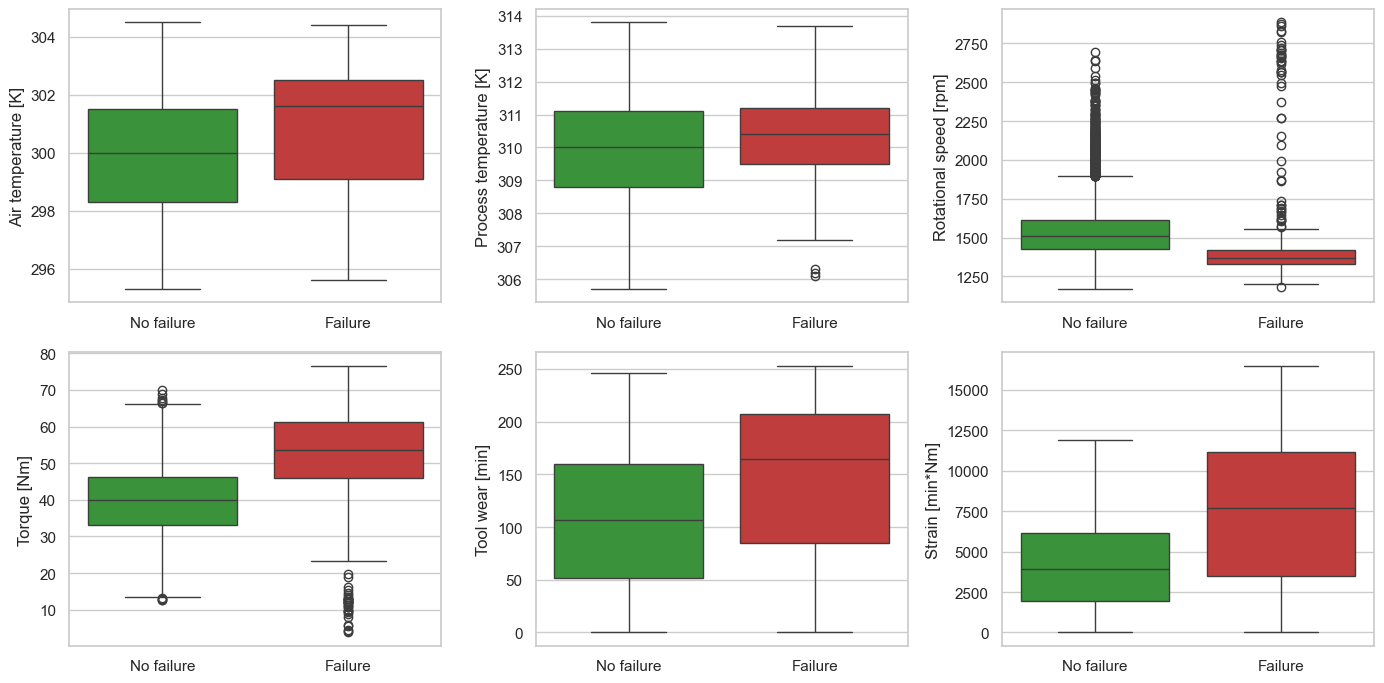

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
cols = RAW_NUMERIC + ['Strain [min*Nm]']
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette=['#2ca02c','#d62728'])
    ax.set_xticklabels(['No failure','Failure']); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## 4. Correlations with failure
Using raw + engineered features.

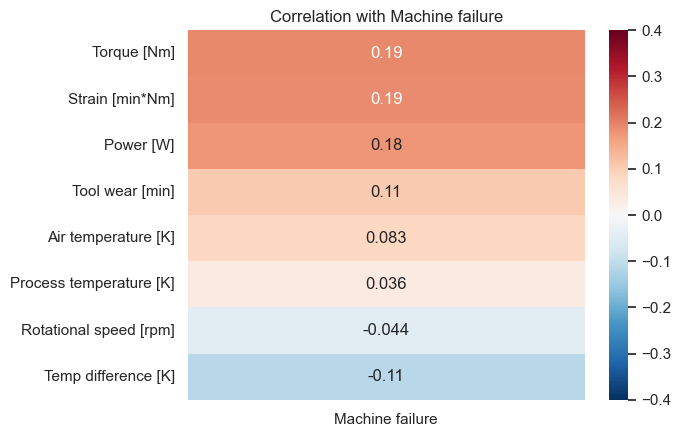

In [5]:
cor = df[NUMERIC_FEATURES + [TARGET]].corr()[[TARGET]].drop(TARGET).sort_values(TARGET, ascending=False)
ax = sns.heatmap(cor, annot=True, cmap='RdBu_r', center=0, vmin=-0.4, vmax=0.4)
ax.set_title('Correlation with Machine failure'); plt.show()

## 5. Failure rate by product quality (Type)

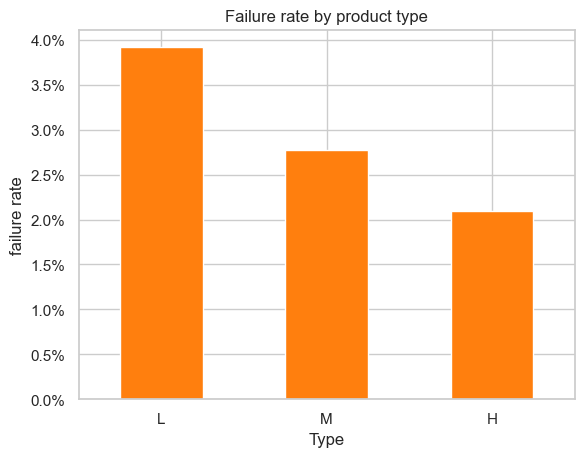

Type
L    0.039167
M    0.027694
H    0.020937
Name: Machine failure, dtype: float64

In [6]:
by_type = df.groupby('Type')[TARGET].mean().reindex(['L','M','H'])
ax = by_type.plot.bar(color='#ff7f0e', rot=0)
ax.set_title('Failure rate by product type'); ax.set_ylabel('failure rate')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x:.1%}')); plt.show()
by_type

## Key takeaways

- **Failures are rare (~3.4%)** → evaluate with PR-AUC / recall, not accuracy.
- **Heat Dissipation (HDF) and Overstrain (OSF)** are the most common failure modes.
- Failing machines tend to show **higher torque, higher tool wear, and a smaller air-to-process temperature gap** — so the engineered **strain** (tool wear x torque) and **temperature difference** features are informative.
- **Lower-quality machines (Type L) fail more often** than M or H.

These insights motivate the engineered features and the model used in `src/train.py`.